In [1]:
import os
import time
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Bidirectional, GRU,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.models import Model

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Set seeds for reproducibility
np.random.seed(42)
tf.keras.utils.set_random_seed(42)


In [2]:
path = r"../Dataset/Processed/FD002"


In [3]:
baseline_comparison_df = pd.read_csv("../Results/comparison_tables/fd002_baseline_comparison.csv")
X_train_fd2 = np.load(os.path.join(path, "x_train.npy"))
X_test_fd2  = np.load(os.path.join(path, "x_test.npy"))

y_train_fd2 = np.load(os.path.join(path, "y_train.npy"))
y_test_fd2  = np.load(os.path.join(path, "y_test.npy"))

X_val_fd2   = np.load(os.path.join(path, "x_val.npy"))
y_val_fd2   = np.load(os.path.join(path, "y_val.npy"))

print(f"Loaded FD002 Arrays: X_train {X_train_fd2.shape}, X_val {X_val_fd2.shape}, X_test {X_test_fd2.shape}")


Loaded FD002 Arrays: X_train (36857, 30, 14), X_val (9362, 30, 14), X_test (259, 30, 14)


In [4]:
def build_hybrid_cnn_gru(input_shape=(30, 14)):
    """
    Builds the state-of-the-art Hybrid CNN-GRU architecture.
    Combines Conv1D feature extraction with Bidirectional GRU sequence modeling.
    """
    inputs = Input(shape=input_shape, name="input_sensors")

    # CNN Feature Extractor (Learns cross-sensor spatial correlations at each cycle)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same', name="conv1d_1")(inputs)
    x = BatchNormalization(name="bn_1")(x)
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same', name="conv1d_2")(x)
    x = BatchNormalization(name="bn_2")(x)

    # Bidirectional GRU for Temporal Tracking (Captures degradation trend forwards & backwards)
    x = Bidirectional(GRU(32, return_sequences=False), name="bi_gru")(x)
    x = Dropout(0.3, name="drop_1")(x)

    # Dense Regression Head
    x = Dense(32, activation='relu', name="dense_1")(x)
    x = Dropout(0.2, name="drop_2")(x)
    outputs = Dense(1, name="rul_output")(x)

    model = Model(inputs=inputs, outputs=outputs, name="Hybrid_CNN_GRU")
    return model

model_hybrid = build_hybrid_cnn_gru(input_shape=(30, 14))
model_hybrid.summary()

Model: "Hybrid_CNN_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_sensors (InputLayer)           │ (None, 30, 14)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 30, 64)              │           2,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_1 (BatchNormalization)            │ (None, 30, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 30, 32)              │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_2 (BatchNormalization)            │ (None, 30, 32)              │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bi_gru (Bidirectional)               │ (None, 64)                  │          12,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_1 (Dropout)                     │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_2 (Dropout)                     │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rul_output (Dense)                   │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,097 (94.13 KB)

 Trainable params: 23,905 (93.38 KB)

 Non-trainable params: 192 (768.00 B)

# Asymmetric Loss Function

In [5]:
def asymmetric_mse(y_true, y_pred, alpha_early=1.0, alpha_late=2.0):
    """
    Custom loss function penalizing overprediction (late prediction) twice as heavily
    as underprediction (early prediction).
    Overpredicting RUL leads to catastrophic unscheduled in-flight engine failures.
    Underpredicting leads only to harmless premature inspection.
    """
    diff = y_pred - y_true
    weight = tf.where(diff < 0, alpha_early, alpha_late)
    return tf.reduce_mean(weight * tf.square(diff))


In [6]:
# Test and verify custom loss function on dummy tensors
y_true_dummy = tf.constant([50.0, 50.0])
y_pred_dummy = tf.constant([40.0, 60.0])  # error = -10 (early), +10 (late)
loss_value = asymmetric_mse(y_true_dummy, y_pred_dummy)
print(f"Asymmetric MSE loss for [-10, +10] errors: {loss_value.numpy():.2f}")

Asymmetric MSE loss for [-10, +10] errors: 150.00


# Train on FD002

In [7]:
os.makedirs('../Models/FD002', exist_ok=True)

# Compile hybrid model with custom asymmetric loss
model_hybrid.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=asymmetric_mse,
    metrics=['mae']
)

callbacks_hybrid = [
    EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
    ModelCheckpoint('../Models/FD002/hybrid_cnn_gru.keras', monitor='val_loss', save_best_only=True)
]

start_time = time.time()
history_hybrid = model_hybrid.fit(
    X_train_fd2, y_train_fd2,
    validation_data=(X_val_fd2, y_val_fd2),
    epochs=100,
    batch_size=64,
    callbacks=callbacks_hybrid,
    verbose=1
)
time_hybrid = time.time() - start_time
print(f"Hybrid model training completed in {time_hybrid:.1f} seconds.")


Epoch 1/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 1649.0968 - mae: 28.1157 - val_loss: 472.8171 - val_mae: 15.6857 - learning_rate: 0.0010
Epoch 2/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 602.4180 - mae: 17.0081 - val_loss: 390.8617 - val_mae: 14.0864 - learning_rate: 0.0010
Epoch 3/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 519.7100 - mae: 15.6895 - val_loss: 407.6072 - val_mae: 14.5494 - learning_rate: 0.0010
Epoch 4/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 475.9163 - mae: 14.9493 - val_loss: 434.6482 - val_mae: 14.3152 - learning_rate: 0.0010
Epoch 5/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 444.9583 - mae: 14.4306 - val_loss: 416.4653 - val_mae: 13.8245 - learning_rate: 0.0010
Epoch 6/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 408.6685 - mae: 13.8533 - val_loss: 457.5525 - val_mae: 14.2107 - learning_rate: 0.0010
Epoch 7/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 379.5975 - mae: 13.3492 - val_loss: 

# Evaluate and Compare Against Baselines

# Evaluate Hybrid model on test set

In [8]:
def nasa_score(y_true, y_pred):
    """
    NASA PHM08 asymmetric scoring function.
    Late predictions (y_pred > y_true) penalize exponentially higher (e^(d/10)-1)
    than early predictions (y_pred < y_true) penalized as (e^(-d/13)-1).
    """
    errors = np.asarray(y_pred).flatten() - np.asarray(y_true).flatten()
    scores = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )
    return float(np.sum(scores))

In [9]:
def evaluate_model_performance(model, X_te, y_te, name="Model"):
    """
    Computes MAE, RMSE, and NASA Score simultaneously.
    """
    y_pred = model.predict(X_te).flatten()
    mae = float(mean_absolute_error(y_te, y_pred))
    rmse = float(np.sqrt(mean_squared_error(y_te, y_pred)))
    score = nasa_score(y_te, y_pred)
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "NASA Score": round(score, 1)}

print("Evaluation functions defined.")

Evaluation functions defined.


In [10]:
metrics_hybrid = evaluate_model_performance(model_hybrid, X_test_fd2, y_test_fd2, "Hybrid CNN-GRU")
metrics_hybrid['Training Time (s)'] = round(time_hybrid, 1)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step 


# Append to baseline comparison table

In [11]:
os.makedirs('../Results/comparison_tables', exist_ok=True)
all_fd2_models = pd.concat([baseline_comparison_df, pd.DataFrame([metrics_hybrid])], ignore_index=True)
all_fd2_models.to_csv('../Results/comparison_tables/fd002_all_models_comparison.csv', index=False)


In [12]:
print("=== Full FD002 Model Comparison (Baselines vs Hybrid) ===")
print(all_fd2_models.to_string(index=False))

=== Full FD002 Model Comparison (Baselines vs Hybrid) ===
         Model   MAE  RMSE  NASA Score  Training Time (s)
           CNN 11.04 14.77      1251.8               36.9
          LSTM 10.93 14.77      1138.4              120.2
           GRU 10.19 13.71       953.7              406.1
Hybrid CNN-GRU 12.95 17.03      1241.7               91.7


# Plot Actual vs Predicted for Hybrid

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


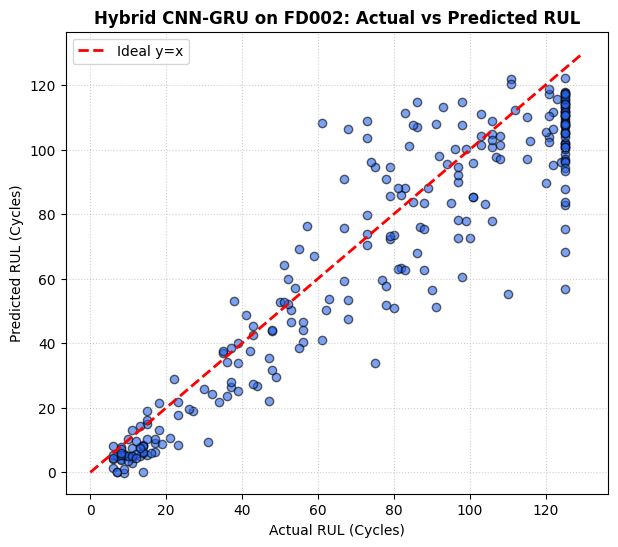

In [13]:
os.makedirs('../Results/FD002_plots', exist_ok=True)
y_pred_hybrid = model_hybrid.predict(X_test_fd2).flatten()
plt.figure(figsize=(7, 6))
plt.scatter(y_test_fd2, y_pred_hybrid, alpha=0.6, edgecolors='k', color='#2563EB')
plt.plot([0, 130], [0, 130], 'r--', lw=2, label='Ideal y=x')
plt.title("Hybrid CNN-GRU on FD002: Actual vs Predicted RUL", fontweight='bold')
plt.xlabel("Actual RUL (Cycles)"); plt.ylabel("Predicted RUL (Cycles)")
plt.legend(); plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('../Results/FD002_plots/fd002_actual_vs_predicted_hybrid.png', dpi=200, bbox_inches='tight')
plt.show()


# Save Pre-trained Model

This model will be the foundation for transfer learning to FD004.

In [14]:
os.makedirs('../Models/FD002', exist_ok=True)
# Save complete pre-trained hybrid model
model_hybrid.save('../Models/FD002/hybrid_cnn_gru.keras')

# Verify that model loads correctly with custom loss
loaded_model = tf.keras.models.load_model(
    '../Models/FD002/hybrid_cnn_gru.keras',
    custom_objects={'asymmetric_mse': asymmetric_mse}
)
print("Successfully verified and saved pre-trained model to Models/FD002/hybrid_cnn_gru.keras")


Successfully verified and saved pre-trained model to Models/FD002/hybrid_cnn_gru.keras
